# Titanic: do dado bruto à submissão

**Autor:** Vinicius Brum  
**Competição:** [Titanic — Machine Learning from Disaster](https://www.kaggle.com/competitions/titanic) (Kaggle)

Este notebook percorre o fluxo completo de uma competição de classificação tabular:

1. explorar os passageiros do Titanic e entender quem tinha mais chance de sobreviver;
2. criar atributos (título, tamanho da família, convés, faixas de tarifa) sem vazar informação do teste;
3. comparar cinco modelos com validação cruzada estratificada de 5 folds;
4. treinar o melhor modelo no conjunto completo e gerar `submissions/submission.csv`.

A métrica oficial da competição é a **acurácia**: a porcentagem de previsões corretas de sobrevivência (`0` ou `1`) nos 418 passageiros do teste oculto.


## 1. Configuração e leitura dos dados

Os arquivos `train.csv` (891 passageiros, com o alvo `Survived`) e `test.csv` (418 passageiros, sem o alvo) devem estar em `data/`. O download oficial está em [kaggle.com/competitions/titanic/data](https://www.kaggle.com/competitions/titanic/data).

O pré-processamento reutilizável vive em `src/features.py` (`TitanicFeatureEngineer` + `ColumnTransformer`).


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.pipeline import Pipeline

# Garante que o notebook funcione tanto a partir da raiz do repositório
# quanto de dentro de notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.features import TitanicFeatureEngineer, build_preprocessor, extract_title
from src.train import (
    RANDOM_STATE,
    default_models,
    evaluate_models,
    fit_best_and_predict,
    load_data,
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.dpi": 110,
})

# Paleta: verde-azulado = sobreviveu, terracota = não sobreviveu.
COR_SURV = "#2A9D8F"
COR_DIED = "#E76F51"
COR_ACCENT = "#264653"

DATA_DIR = ROOT / "data"
SUBMISSION_PATH = ROOT / "submissions" / "submission.csv"

X, y, test = load_data(DATA_DIR)
train = X.copy()
train["Survived"] = y

print(f"Raiz do projeto: {ROOT}")
print(f"Treino: {train.shape[0]} linhas, {train.shape[1]} colunas")
print(f"Teste:  {test.shape[0]} linhas, {test.shape[1]} colunas")
print("Colunas do treino:", list(train.columns))
print("Colunas do teste: ", list(test.columns))
assert len(train) == 891, "O treino oficial tem 891 passageiros."
assert len(test) == 418, "O teste oficial tem 418 passageiros."
assert list(train.columns) == [
    "PassengerId", "Pclass", "Name", "Sex", "Age", "SibSp",
    "Parch", "Ticket", "Fare", "Cabin", "Embarked", "Survived",
]
assert list(test.columns) == [
    "PassengerId", "Pclass", "Name", "Sex", "Age", "SibSp",
    "Parch", "Ticket", "Fare", "Cabin", "Embarked",
]
train.head()


Raiz do projeto: /workspace/kaggle-titanic
Treino: 891 linhas, 12 colunas
Teste:  418 linhas, 11 colunas
Colunas do treino: ['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'Survived']
Colunas do teste:  ['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Survived
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,0
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,1
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,1
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,0


## 2. Análise exploratória

Antes de modelar, vale entender o desbalanceamento do alvo e as relações mais fortes com a sobrevivência. No treino, **cerca de 38%** dos passageiros sobreviveram — um pouco abaixo de metade, então um modelo que chute sempre “não sobreviveu” já acertaria ~62%.


In [2]:
print("Taxa de sobrevivência no treino: "
      f"{train['Survived'].mean():.1%} ({int(y.sum())} de {len(y)})")
print("\nValores ausentes no treino:")
missing = (
    train.isna().sum()
    .rename("n_ausentes")
    .to_frame()
    .assign(pct=lambda d: (d["n_ausentes"] / len(train) * 100).round(1))
)
missing = missing[missing["n_ausentes"] > 0].sort_values("n_ausentes", ascending=False)
display(missing)

print("Valores ausentes no teste:")
missing_test = (
    test.isna().sum()
    .rename("n_ausentes")
    .to_frame()
    .assign(pct=lambda d: (d["n_ausentes"] / len(test) * 100).round(1))
)
display(missing_test[missing_test["n_ausentes"] > 0])


Taxa de sobrevivência no treino: 38.4% (342 de 891)

Valores ausentes no treino:


,n_ausentes,pct
Cabin,687,77.1
Age,177,19.9
Embarked,2,0.2


Valores ausentes no teste:


,n_ausentes,pct
Age,86,20.6
Fare,1,0.2
Cabin,327,78.2


Há **177 idades ausentes** no treino (20%) e 86 no teste; a cabine está ausente na maior parte dos casos (687 e 327). No teste falta **uma tarifa**, e no treino faltam **dois portos de embarque**. Esses buracos precisam ser imputados com estatísticas aprendidas só no fold de treino.


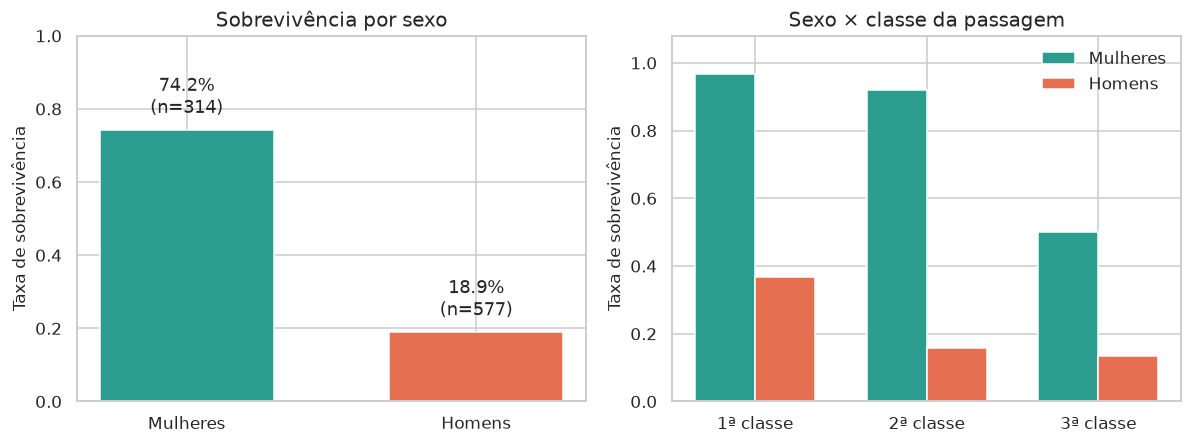

Taxa por sexo e classe:


taxa    n
Sex    Pclass            
female 1       96.8%   94
       2       92.1%   76
       3       50.0%  144
male   1       36.9%  122
       2       15.7%  108
       3       13.5%  347

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

sexo = (
    train.groupby("Sex")["Survived"]
    .agg(taxa="mean", n="count")
    .reindex(["female", "male"])
)
axes[0].bar(
    ["Mulheres", "Homens"],
    sexo["taxa"],
    color=[COR_SURV, COR_DIED],
    width=0.6,
)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Taxa de sobrevivência")
axes[0].set_title("Sobrevivência por sexo")
for i, (taxa, n) in enumerate(zip(sexo["taxa"], sexo["n"])):
    axes[0].text(i, taxa + 0.03, f"{taxa:.1%}\n(n={n})", ha="center", va="bottom")

classe_sexo = (
    train.groupby(["Pclass", "Sex"])["Survived"]
    .mean()
    .unstack()
    .reindex(columns=["female", "male"])
)
x = np.arange(3)
w = 0.35
axes[1].bar(x - w / 2, classe_sexo["female"], width=w, label="Mulheres", color=COR_SURV)
axes[1].bar(x + w / 2, classe_sexo["male"], width=w, label="Homens", color=COR_DIED)
axes[1].set_xticks(x, ["1ª classe", "2ª classe", "3ª classe"])
axes[1].set_ylim(0, 1.08)
axes[1].set_ylabel("Taxa de sobrevivência")
axes[1].set_title("Sexo × classe da passagem")
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

print("Taxa por sexo e classe:")
display(
    train.groupby(["Sex", "Pclass"])["Survived"]
    .agg(taxa="mean", n="count")
    .assign(taxa=lambda d: d["taxa"].map(lambda v: f"{v:.1%}"))
)


**Leitura.** O sexo e a classe dominam o problema — o famoso “mulheres e crianças primeiro”, filtrado pelo acesso aos botes:

- mulheres sobreviveram a **74,2%**, homens a apenas **18,9%**;
- mulheres da 1ª e da 2ª classe: **96,8%** e **92,1%**;
- homens da 3ª classe, o maior grupo (347 pessoas): apenas **13,5%**.

Qualquer modelo razoável precisa capturar essa interação. Ainda assim, há sinal extra em idade, família e título, como vemos a seguir.


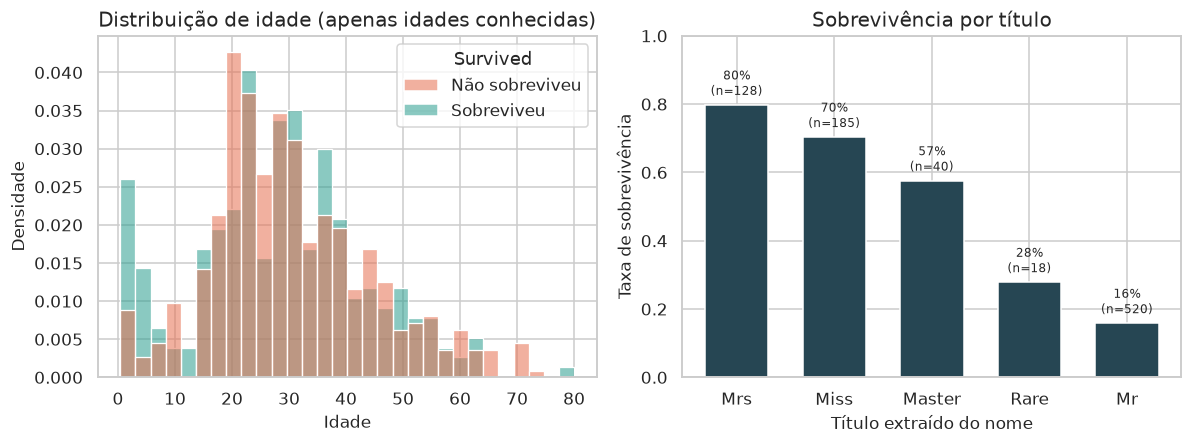

Mediana de idade por título (base da imputação):


,mediana,n
Title,,
Master,3.5,36
Miss,21.0,149
Mr,30.0,401
Mrs,35.0,111
Rare,50.0,17


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

idade = train.dropna(subset=["Age"])
sns.histplot(
    data=idade,
    x="Age",
    hue="Survived",
    bins=30,
    stat="density",
    common_norm=False,
    palette={0: COR_DIED, 1: COR_SURV},
    alpha=0.55,
    ax=axes[0],
)
axes[0].set_title("Distribuição de idade (apenas idades conhecidas)")
axes[0].set_xlabel("Idade")
axes[0].set_ylabel("Densidade")
# Legenda com nomes em português
leg = axes[0].get_legend()
if leg is not None:
    for text, label in zip(leg.get_texts(), ["Não sobreviveu", "Sobreviveu"]):
        text.set_text(label)

train = train.copy()
train["Title"] = train["Name"].map(extract_title)
titulo = (
    train.groupby("Title")["Survived"]
    .agg(taxa="mean", n="count")
    .reindex(["Mrs", "Miss", "Master", "Rare", "Mr"])
    .dropna()
)
axes[1].bar(titulo.index, titulo["taxa"], color=COR_ACCENT, width=0.65)
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Taxa de sobrevivência")
axes[1].set_xlabel("Título extraído do nome")
axes[1].set_title("Sobrevivência por título")
for i, (taxa, n) in enumerate(zip(titulo["taxa"], titulo["n"])):
    axes[1].text(i, taxa + 0.03, f"{taxa:.0%}\n(n={int(n)})", ha="center", fontsize=8)
fig.tight_layout()
plt.show()

print("Mediana de idade por título (base da imputação):")
display(train.groupby("Title")["Age"].agg(mediana="median", n="count"))


**Leitura.** O título não é só um proxy de sexo: **Master** (meninos) sobreviveu a **57,5%**, contra **15,7%** dos **Mr**. A mediana de idade de Master é **3,5 anos**, a de Mr é **30**. Por isso a imputação de idade é feita **por título**, e não por uma mediana global — completar a idade de uma criança com 28 anos distorceria o sinal.


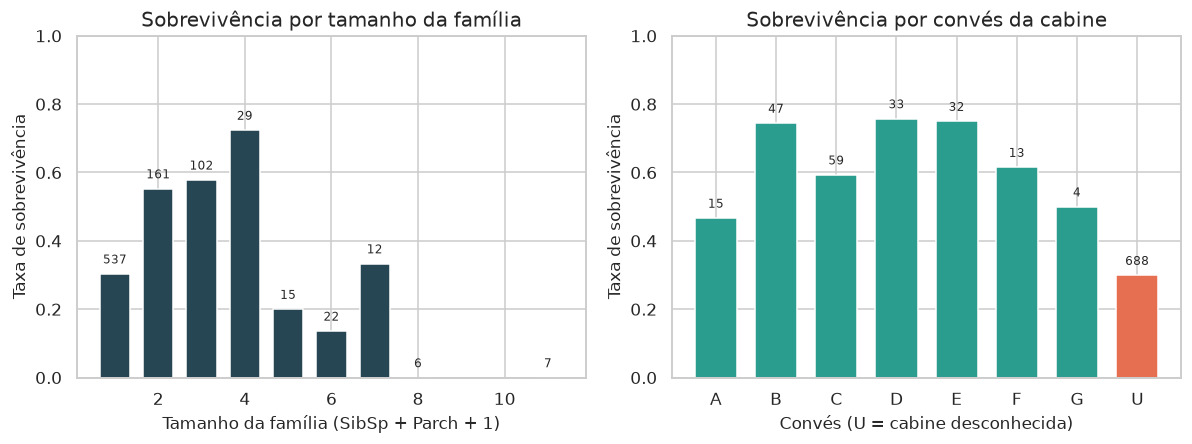

In [5]:
train["FamilySize"] = train["SibSp"] + train["Parch"] + 1
train["Deck"] = train["Cabin"].fillna("U").astype(str).str[0].replace({"T": "U"})

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

fam = train.groupby("FamilySize")["Survived"].agg(taxa="mean", n="count")
axes[0].bar(fam.index, fam["taxa"], color=COR_ACCENT, width=0.7)
axes[0].set_xlabel("Tamanho da família (SibSp + Parch + 1)")
axes[0].set_ylabel("Taxa de sobrevivência")
axes[0].set_title("Sobrevivência por tamanho da família")
axes[0].set_ylim(0, 1)
for i, row in fam.iterrows():
    axes[0].text(i, row["taxa"] + 0.03, str(int(row["n"])), ha="center", fontsize=8)

deck = train.groupby("Deck")["Survived"].agg(taxa="mean", n="count").sort_index()
cores = [COR_DIED if d == "U" else COR_SURV for d in deck.index]
axes[1].bar(deck.index, deck["taxa"], color=cores, width=0.7)
axes[1].set_xlabel("Convés (U = cabine desconhecida)")
axes[1].set_ylabel("Taxa de sobrevivência")
axes[1].set_title("Sobrevivência por convés da cabine")
axes[1].set_ylim(0, 1)
for i, (idx, row) in enumerate(deck.iterrows()):
    axes[1].text(i, row["taxa"] + 0.03, str(int(row["n"])), ha="center", fontsize=8)
fig.tight_layout()
plt.show()


**Leitura.** Famílias **pequenas ou médias** (2 a 4 pessoas) sobreviveram bem mais (55%–72%) do que quem viajava **sozinho** (30%) ou em **famílias muito grandes** (0%–20% acima de 4). Ter a cabine registrada também é informativo: nos conveses B, D e E a sobrevivência passa de **74%**, enquanto a maioria sem cabine (`U`, 687 passageiros) fica em **30%**. Isso mistura classe social e o simples fato de o registro da cabine ter sido preservado, mas ainda é um atributo útil (`HasCabin` + `Deck`).


## 3. Engenharia de atributos

O transformador `TitanicFeatureEngineer` aprende no `fit` (apenas no fold de treino) e aplica no `transform`:

| Atributo | Como é criado |
| --- | --- |
| `Title` | Título do nome, normalizado para `Mr`, `Mrs`, `Miss`, `Master` ou `Rare` |
| `FamilySize` e `IsAlone` | `SibSp + Parch + 1`; indicador de quem viajava sozinho |
| `Age` | Imputada pela **mediana do título**; fallback para a mediana global |
| `Fare` | Imputada pela mediana da **classe** (`Pclass`) |
| `FareBin` | Faixas em quantis cujos cortes vêm do treino |
| `FarePerPerson` | `Fare / FamilySize` |
| `Deck` e `HasCabin` | Primeira letra da cabine, ou `U` se ausente |
| `Embarked` | Imputado pela moda do treino (na prática, `S`) |

Em seguida um `ColumnTransformer` padroniza as variáveis numéricas e aplica *one-hot* nas categóricas. Assim, regressão logística, MLP e árvores recebem a mesma matriz.


In [6]:
engineer = TitanicFeatureEngineer().fit(X, y)
exemplo = engineer.transform(X.head(8))[
    [
        "Name", "Title", "Age", "FamilySize", "IsAlone",
        "Fare", "FarePerPerson", "FareBin", "Deck", "HasCabin", "Embarked",
    ]
]
display(exemplo)

prep = build_preprocessor()
Xt = prep.fit_transform(X, y)
nomes = prep.named_steps["preprocess"].get_feature_names_out()
print(f"Matriz após o pipeline: {Xt.shape[0]} × {Xt.shape[1]} atributos")
print("Atributos:", list(nomes))


,Name,Title,Age,FamilySize,IsAlone,Fare,FarePerPerson,FareBin,Deck,HasCabin,Embarked
0,"Braund, Mr. Owen Harris",Mr,22.0,2,0,7.2500,3.62500,Q1,U,0,S
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,38.0,2,0,71.2833,35.64165,Q4,C,1,C
2,"Heikkinen, Miss. Laina",Miss,26.0,1,1,7.9250,7.92500,Q2,U,0,S
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,35.0,2,0,53.1000,26.55000,Q4,C,1,S
4,"Allen, Mr. William Henry",Mr,35.0,1,1,8.0500,8.05000,Q2,U,0,S
5,"Moran, Mr. James",Mr,30.0,1,1,8.4583,8.45830,Q2,U,0,Q
6,"McCarthy, Mr. Timothy J",Mr,54.0,1,1,51.8625,51.86250,Q4,E,1,S
7,"Palsson, Master. Gosta Leonard",Master,2.0,5,0,21.0750,4.21500,Q3,U,0,S


Matriz após o pipeline: 891 × 34 atributos
Atributos: ['Age', 'Fare', 'FamilySize', 'SibSp', 'Parch', 'FarePerPerson', 'HasCabin', 'Pclass_1', 'Pclass_2', 'Pclass_3', 'Sex_female', 'Sex_male', 'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Deck_A', 'Deck_B', 'Deck_C', 'Deck_D', 'Deck_E', 'Deck_F', 'Deck_G', 'Deck_U', 'IsAlone_0', 'IsAlone_1', 'FareBin_Q1', 'FareBin_Q2', 'FareBin_Q3', 'FareBin_Q4']


## 4. Comparação de modelos (validação cruzada estratificada)

Comparamos cinco estimadores, todos atrás do mesmo pipeline, com **5 folds estratificados** (`random_state=42`). A estratificação preserva a taxa de sobrevivência em cada fold, o que importa num alvo desbalanceado.

- **Regressão logística** — baseline linear, interpretável.
- **Random Forest** — bagging de árvores, profundidade limitada para não superajustar 891 linhas.
- **Gradient Boosting** (scikit-learn) — boosting clássico, forte em tabular pequeno.
- **XGBoost** — boosting regularizado, mesmo espírito, outra implementação.
- **Rede neural (MLPClassifier)** — MLP simples `(64, 32)` do scikit-learn, com early stopping. Entra para comparação: neste conjunto pequeno e tabular, redes rasas raramente superam ensembles de árvores.

Não fizemos uma busca exaustiva de hiperparâmetros de propósito: com tão poucas linhas, um grid grande costuma inflar a acurácia da validação cruzada e piorar a submissão pública.


In [7]:
resultados = evaluate_models(X, y)

tabela = resultados.copy()
tabela["Acurácia CV"] = tabela["cv_media"].map(lambda v: f"{v:.2%}")
tabela["Desvio"] = tabela["cv_desvio"].map(lambda v: f"{v:.2%}")
tabela["Folds"] = tabela["folds"].map(
    lambda fs: ", ".join(f"{s:.2%}" for s in fs)
)
tabela = tabela.rename(columns={"modelo": "Modelo"})[
    ["Modelo", "Acurácia CV", "Desvio", "Folds"]
]
display(tabela)

melhor = resultados.iloc[0]["modelo"]
melhor_media = resultados.iloc[0]["cv_media"]
melhor_desvio = resultados.iloc[0]["cv_desvio"]
print(f"Modelo escolhido: {melhor} ({melhor_media:.2%} ± {melhor_desvio:.2%})")


Regressão Logística: 0.8294 ± 0.0178 (folds=[0.8492, 0.8258, 0.7978, 0.8315, 0.8427])


Random Forest: 0.8384 ± 0.0137 (folds=[0.8547, 0.8315, 0.8202, 0.8315, 0.8539])


Gradient Boosting: 0.8440 ± 0.0151 (folds=[0.8715, 0.8315, 0.8315, 0.8371, 0.8483])


XGBoost: 0.8428 ± 0.0193 (folds=[0.8715, 0.8539, 0.8315, 0.8146, 0.8427])


Rede neural (MLP): 0.8103 ± 0.0203 (folds=[0.7933, 0.8371, 0.7809, 0.8202, 0.8202])


,Modelo,Acurácia CV,Desvio,Folds
0,Gradient Boosting,84.40%,1.51%,"87.15%, 83.15%, 83.15%, 83.71%, 84.83%"
1,XGBoost,84.28%,1.93%,"87.15%, 85.39%, 83.15%, 81.46%, 84.27%"
2,Random Forest,83.84%,1.37%,"85.47%, 83.15%, 82.02%, 83.15%, 85.39%"
3,Regressão Logística,82.94%,1.78%,"84.92%, 82.58%, 79.78%, 83.15%, 84.27%"
4,Rede neural (MLP),81.03%,2.03%,"79.33%, 83.71%, 78.09%, 82.02%, 82.02%"


Modelo escolhido: Gradient Boosting (84.40% ± 1.51%)


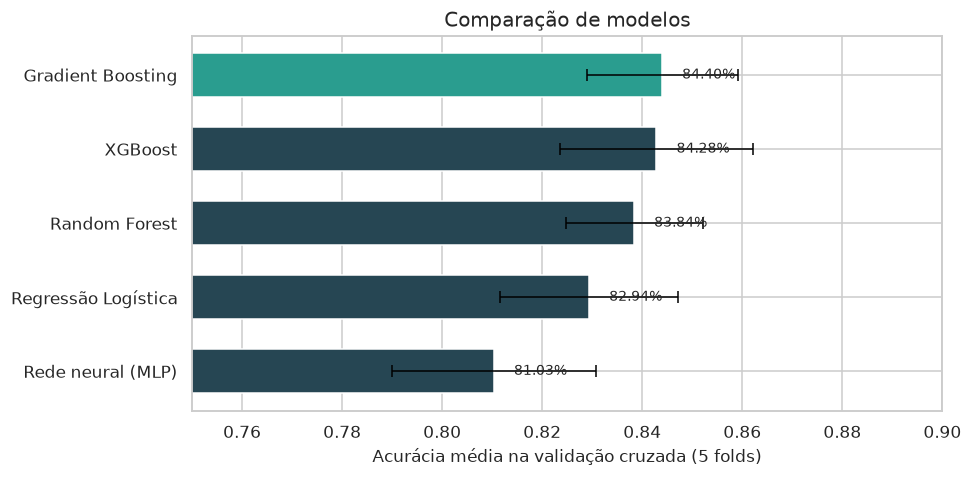

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ordem = resultados.sort_values("cv_media")
cores_bar = [COR_SURV if m == melhor else COR_ACCENT for m in ordem["modelo"]]
ax.barh(ordem["modelo"], ordem["cv_media"], color=cores_bar, height=0.6)
ax.errorbar(
    ordem["cv_media"],
    ordem["modelo"],
    xerr=ordem["cv_desvio"],
    fmt="none",
    ecolor="black",
    capsize=4,
    lw=1,
)
ax.set_xlim(0.75, 0.90)
ax.set_xlabel("Acurácia média na validação cruzada (5 folds)")
ax.set_title("Comparação de modelos")
for y_pos, (_, row) in enumerate(ordem.iterrows()):
    ax.text(
        row["cv_media"] + 0.004,
        y_pos,
        f"{row['cv_media']:.2%}",
        va="center",
        fontsize=9,
    )
fig.tight_layout()
plt.show()


## 5. Modelo final, importância dos atributos e submissão

O melhor modelo na validação cruzada é retreinado em **todo** o conjunto de treino e gera previsões para os 418 passageiros do teste. O arquivo segue o formato exigido pelo Kaggle: `PassengerId,Survived`.


In [9]:
submission = fit_best_and_predict(X, y, test, melhor)
SUBMISSION_PATH.parent.mkdir(parents=True, exist_ok=True)
submission.to_csv(SUBMISSION_PATH, index=False)

print(f"Arquivo: {SUBMISSION_PATH}")
print(f"Linhas: {len(submission)} (esperado: 418)")
print(f"IDs: {submission['PassengerId'].min()}–{submission['PassengerId'].max()}")
print(
    "Previsões: "
    f"{int((submission['Survived'] == 1).sum())} sobreviventes "
    f"({submission['Survived'].mean():.1%}) e "
    f"{int((submission['Survived'] == 0).sum())} não sobreviventes"
)
display(submission.head())

assert len(submission) == 418
assert list(submission.columns) == ["PassengerId", "Survived"]
assert submission["Survived"].isin([0, 1]).all()
assert submission["PassengerId"].is_unique


Arquivo: /workspace/kaggle-titanic/submissions/submission.csv
Linhas: 418 (esperado: 418)
IDs: 892–1309
Previsões: 159 sobreviventes (38.0%) e 259 não sobreviventes


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


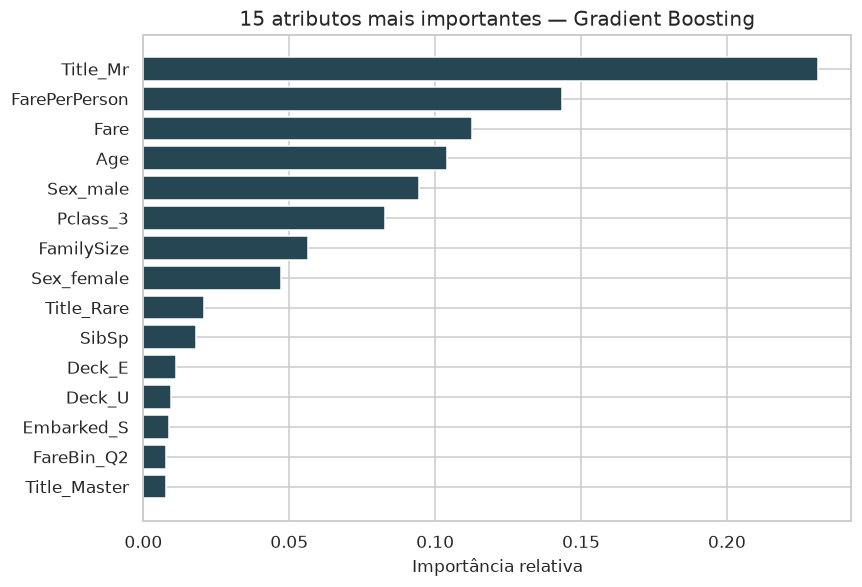

In [10]:
# Importâncias do modelo escolhido (árvores). Se o vencedor não tiver
# feature_importances_, o gráfico é ignorado.
estimador = default_models()[melhor]
pipe_final = Pipeline([
    ("prep", build_preprocessor()),
    ("model", estimador),
])
pipe_final.fit(X, y)
modelo_ajustado = pipe_final.named_steps["model"]

if hasattr(modelo_ajustado, "feature_importances_"):
    nomes_attr = pipe_final.named_steps["prep"].named_steps["preprocess"].get_feature_names_out()
    imp = (
        pd.DataFrame({"atributo": nomes_attr, "importancia": modelo_ajustado.feature_importances_})
        .sort_values("importancia", ascending=False)
        .head(15)
        .iloc[::-1]
    )
    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.barh(imp["atributo"], imp["importancia"], color=COR_ACCENT)
    ax.set_xlabel("Importância relativa")
    ax.set_title(f"15 atributos mais importantes — {melhor}")
    fig.tight_layout()
    plt.show()
else:
    print(f"{melhor} não expõe feature_importances_; gráfico omitido.")


## 6. Conclusões e próximos passos

- Sexo, classe e título carregam a maior parte do sinal. A engenharia de atributos (família, convés, imputação de idade por título) ajuda, mas não substitui esse padrão principal.
- Ensembles de árvores saíram à frente da regressão logística e, principalmente, da MLP. Isso é esperado: o Titanic tem poucas linhas, atributos mistos e relações já bem capturadas por árvores.
- **Nota de portfólio:** este projeto mostra que o fluxo de uma competição de classificação está no lugar (exploração, pipeline reproduzível, validação honesta, submissão). Ele **não** basta, sozinho, para evidenciar experiência com redes neurais profundas — a MLP entra aqui só como comparação. Para isso, o próximo passo natural é uma competição de imagem ou texto (ou uma Playground Series mais recente).

Para enviar a submissão, faça o upload de `submissions/submission.csv` na [página da competição](https://www.kaggle.com/competitions/titanic/submit). A acurácia da validação cruzada costuma ficar um pouco acima da leaderboard pública: o teste oculto é pequeno e ruidoso, e perseguir a leaderboard é a forma mais rápida de superajustar.
